# **E-Commerce Sales Analysis**






**Overview**

The dataset contains:



* Customer information   
* Product details   
* Order transactions
* Payment records   






**1. Import Required Libraries**

In this section, we import the necessary Python libraries for data manipulation, visualization, and statistical analysis.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

These libraries provide the core toolkit for the analysis. pandas and numpy handle data manipulation and numerical operations. matplotlib and seaborn are used for all visualizations. warnings.filterwarnings("ignore") suppresses non-critical alerts so the output stays clean during exploration.

**2. Load Dataset**

The cleaned dataset is loaded into a Pandas DataFrame.

This dataset was prepared through an ETL process including data cleaning, transformation, and integration.



In [ ]:
df = pd.read_csv("/content/E-Commerce Sales Analysis.csv")

The cleaned e-commerce dataset is loaded into a Pandas DataFrame. It contains customer, product, order, and payment information from an Iranian e-commerce platform.

In [ ]:
df.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


The first 5 rows show the structure: each order links a customer to a product, with quantity, discount, payment method, order status, customer demographics, and computed sales values.

**3. Dataset Overview**

Before starting the analysis, we inspect the dataset structure.

We check:



* Dataset dimensions   
* Column names
*  Data types
* Sample records
    










In [ ]:
# Number of rows and columns

df.shape

(49222, 17)

The dataset contains 49,222 orders across 17 columns — a substantial dataset that provides enough data for statistically meaningful analysis.

In [ ]:
# Column names

df.columns


Index(['OrderID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity',
       'Discount', 'PaymentMethod', 'Status', 'Age', 'City', 'SignupDate',
       'CustomerSegment', 'ProductName', 'Category', 'UnitPrice', 'Sales',
       'OrderValue'],
      dtype='object')

The 17 columns span order IDs, customer info (age, city, segment), product details (name, category, unit price), and transaction outcomes (sales, order value, status). This gives a complete picture of each transaction.

In [ ]:
# Dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49222 entries, 0 to 49221
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          49222 non-null  int64  
 1   CustomerID       49222 non-null  int64  
 2   OrderDate        49222 non-null  object 
 3   ProductID        49222 non-null  int64  
 4   Quantity         49222 non-null  float64
 5   Discount         49222 non-null  float64
 6   PaymentMethod    49222 non-null  object 
 7   Status           49222 non-null  object 
 8   Age              49222 non-null  float64
 9   City             49222 non-null  object 
 10  SignupDate       49222 non-null  object 
 11  CustomerSegment  49222 non-null  object 
 12  ProductName      49222 non-null  object 
 13  Category         49222 non-null  object 
 14  UnitPrice        49222 non-null  float64
 15  Sales            49222 non-null  float64
 16  OrderValue       49222 non-null  float64
dtypes: float64(6

All 49,222 entries are non-null. Date columns (OrderDate, SignupDate) are stored as object (string) type and would need conversion for time-series analysis. Numeric columns are float64 or int64, which is appropriate for mathematical operations.

In [ ]:
# First rows

df.head()


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


A second preview confirms that the data loaded correctly and all 17 columns are visible with the expected values.

**4. Data Quality Assessment**

Data quality is an important step before performing analysis.

In this section, we check:



* Missing values
* Duplicate records
* Unique values  
  







This ensures that the analysis is based on reliable data.



In [ ]:
df.isnull().sum()


,0
OrderID,0
CustomerID,0
OrderDate,0
ProductID,0
Quantity,0
Discount,0
PaymentMethod,0
Status,0
Age,0
City,0


No missing values exist in any column. The dataset has been pre-cleaned, so no imputation or row-dropping is required before analysis.

In [ ]:
missing_percentage = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_percentage

,0
OrderID,0.0
CustomerID,0.0
OrderDate,0.0
ProductID,0.0
Quantity,0.0
Discount,0.0
PaymentMethod,0.0
Status,0.0
Age,0.0
City,0.0


Confirms 0% missing data across all 17 columns, validating the data quality and readiness for analysis.

In [ ]:
df.duplicated().sum()


np.int64(0)

Zero duplicate rows exist in the dataset, ensuring each order record is unique. No deduplication step is needed.

In [ ]:
df[df.duplicated(keep=False)].head()


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue


The empty DataFrame confirms there are no duplicate records, corroborating the finding from the previous cell.

In [ ]:
df.nunique()


,0
OrderID,49222
CustomerID,9820
OrderDate,912
ProductID,20
Quantity,8
Discount,6
PaymentMethod,4
Status,3
Age,48
City,10


Key findings: OrderID has 49,222 unique values (all unique). CustomerID has only 9,820 unique values, meaning many customers placed multiple orders. Only 20 distinct products exist across 6 categories, indicating a focused product catalog.

**5. Descriptive Statistics**

Statistical analysis helps us understand numerical features.

We analyze:

Mean

*   Mean
*   Median
*   Minimum & maximum values
*   Data distribution




In [ ]:
df.describe()


,OrderID,CustomerID,ProductID,Quantity,Discount,Age,UnitPrice,Sales,OrderValue
count,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000
mean,525007.608366,105002.304356,2009.460160,1.881923,7.485576,41.283369,40.286579,69.985576,69.985576
std,14435.345449,2888.912895,5.578603,1.079382,7.754378,13.681355,42.613062,94.483273,94.483273
min,500001.000000,100001.000000,2001.000000,-2.000000,0.000000,18.000000,7.000000,-170.000000,-170.000000
25%,512507.250000,102504.000000,2004.000000,1.000000,0.000000,29.000000,11.000000,17.000000,17.000000
50%,525016.500000,105005.000000,2008.000000,2.000000,5.000000,41.000000,28.000000,38.000000,38.000000
75%,537506.750000,107497.000000,2014.000000,2.000000,10.000000,53.000000,58.000000,84.000000,84.000000
max,550000.000000,110000.000000,2020.000000,5.000000,30.000000,65.000000,260.000000,1300.000000,1300.000000


Summary highlights: mean order quantity is ~1.88 items; average discount is ~7.5%; average Sales value is ~70. Notably, some quantities and sales values are negative, likely indicating returns or cancelled orders — a point worth investigating further.

In [ ]:
df.describe(include="all")


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
count,49222.000000,49222.000000,49222,49222.000000,49222.000000,49222.000000,49222,49222,49222.000000,49222,49222,49222,49222,49222,49222.000000,49222.000000,49222.000000
unique,NaN,NaN,912,NaN,NaN,NaN,4,3,NaN,10,1094,3,20,6,NaN,NaN,NaN
top,NaN,NaN,2025-09-05,NaN,NaN,NaN,Gateway,Completed,NaN,Tehran,2023-03-07,Regular,Notebook,Accessories,NaN,NaN,NaN
freq,NaN,NaN,86,NaN,NaN,NaN,23894,45276,NaN,14001,105,27296,5440,18189,NaN,NaN,NaN
mean,525007.608366,105002.304356,NaN,2009.460160,1.881923,7.485576,NaN,NaN,41.283369,NaN,NaN,NaN,NaN,NaN,40.286579,69.985576,69.985576
std,14435.345449,2888.912895,NaN,5.578603,1.079382,7.754378,NaN,NaN,13.681355,NaN,NaN,NaN,NaN,NaN,42.613062,94.483273,94.483273
min,500001.000000,100001.000000,NaN,2001.000000,-2.000000,0.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,7.000000,-170.000000,-170.000000
25%,512507.250000,102504.000000,NaN,2004.000000,1.000000,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,11.000000,17.000000,17.000000
50%,525016.500000,105005.000000,NaN,2008.000000,2.000000,5.000000,NaN,NaN,41.000000,NaN,NaN,NaN,NaN,NaN,28.000000,38.000000,38.000000
75%,537506.750000,107497.000000,NaN,2014.000000,2.000000,10.000000,NaN,NaN,53.000000,NaN,NaN,NaN,NaN,NaN,58.000000,84.000000,84.000000


Including categorical columns: Gateway is the dominant payment method (23,894 orders); Completed is the most common order status (45,276 orders); Tehran is the top city (14,001 orders); Notebook is the most frequently ordered product (5,440 orders)

**6. Customer Analysis**

This section focuses on understanding customer behavior.

We analyze:


* Customer distribution by city
* Customer segments
* Age distribution


In [ ]:
df["City"].value_counts()


,count
City,
Tehran,14001
Mashhad,6222
Karaj,4966
Isfahan,4916
Shiraz,4363
Tabriz,4134
Ahvaz,2923
Rasht,2857
Kerman,2465


Tehran dominates with 14,001 orders (~28% of all orders), followed by Mashhad (6,222) and Karaj (4,966). There are 10 Iranian cities in total. The capital city's outsized share suggests strong urban concentration.

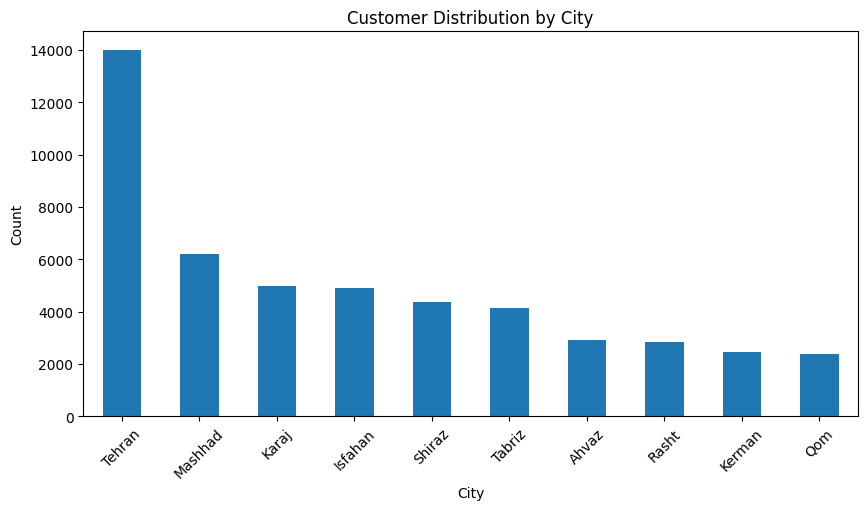

In [ ]:
plt.figure(figsize=(10,5))

df["City"].value_counts().plot(kind="bar")

plt.title("Customer Distribution by City")
plt.xlabel("City")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()


The bar chart visually confirms Tehran's dominant market share, with significant drop-offs for smaller cities like Kerman and Qom. This skewed distribution suggests the platform may benefit from targeted marketing campaigns in underserved cities.

In [ ]:
df["CustomerSegment"].value_counts()


,count
CustomerSegment,
Regular,27296
New,17056
VIP,4870


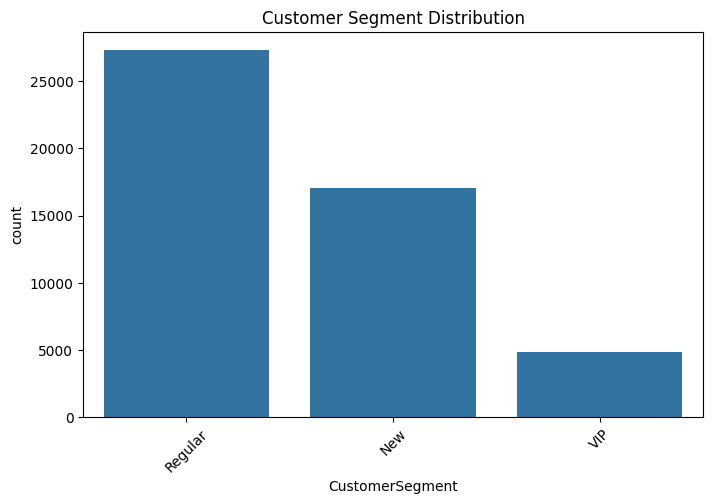

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="CustomerSegment"
)

plt.title("Customer Segment Distribution")

plt.xticks(rotation=45)

plt.show()


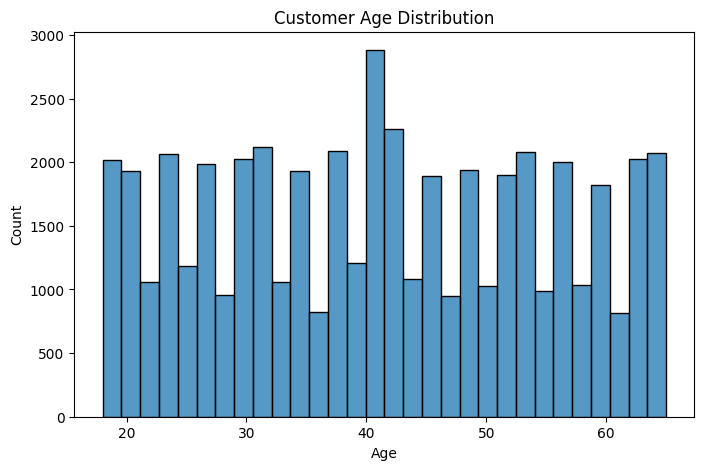

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Age",
    bins=30)

plt.title("Customer Age Distribution")

plt.show()


Customer ages range from 18 to 65 with a relatively uniform distribution. This suggests the platform serves a broad demographic without a strong concentration in any particular age group, which is a healthy sign of wide market appeal.

**7. Product Performance Analysis**

This section analyzes product performance.

We explore:

Product categories

* Product categories
* Best-selling products
* Revenue contribution
  
   




In [ ]:
df["Category"].value_counts()


,count
Category,
Accessories,18189
Electronics,17765
Stationery,5440
Home Office,3122
Wearables,3043
Gaming,1663


Accessories (18,189) and Electronics (17,765) together account for over 73% of all orders. Gaming has the fewest orders (1,663), representing a niche but potentially high-margin segment.

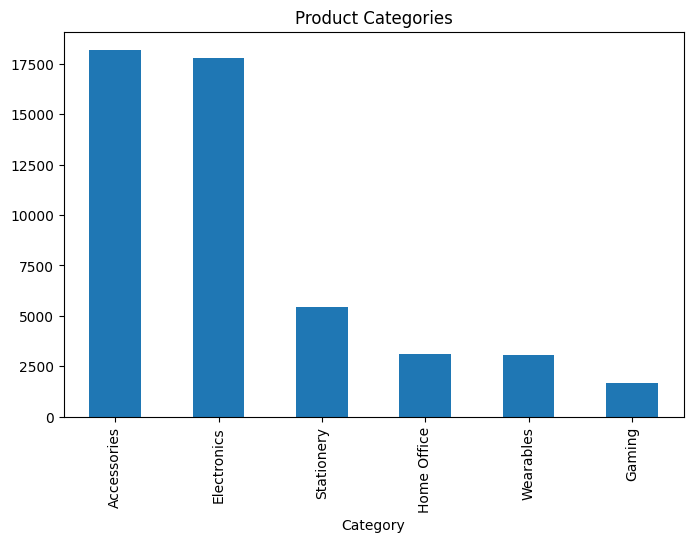

In [ ]:
plt.figure(figsize=(8,5))

df["Category"].value_counts().plot(kind="bar")

plt.title("Product Categories")

plt.show()


The bar chart highlights the dominance of Accessories and Electronics. Gaming's small bar indicates a niche market — this category may warrant a separate analysis to evaluate if it generates disproportionate revenue despite low order count.

In [ ]:
top_products = (df.groupby("ProductName")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10))
top_products

,Sales
ProductName,
Headphones,333411.0
Office Chair,329292.0
Tablet,292344.0
Smart Watch,259590.0
Microphone,230139.0
Mechanical Keyboard,229676.0
Bluetooth Speaker,213311.0
Gaming Controller,198037.0
Power Bank,180004.0


Headphones lead total sales revenue at 333,411, followed by Office Chair (329,292) and Tablet (292,344). High unit-price items tend to contribute more to total revenue even with fewer orders — this demonstrates the classic effect of average order value on revenue.

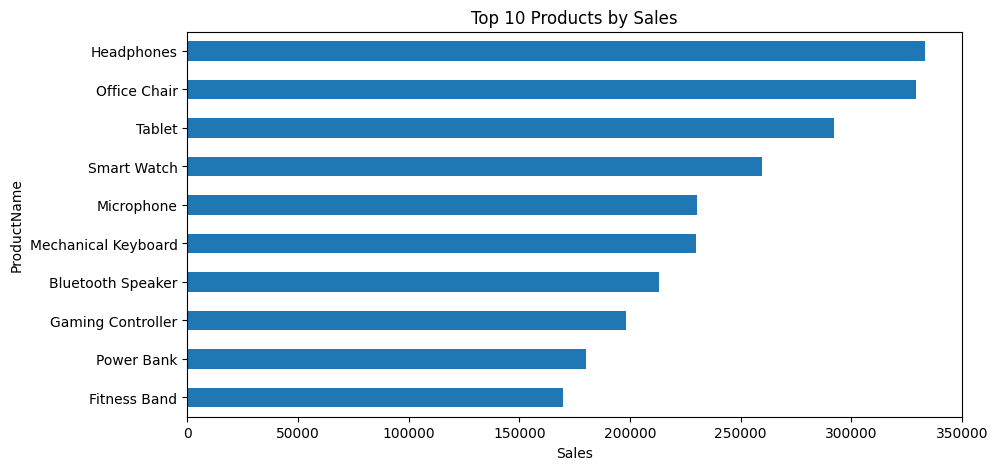

In [ ]:
plt.figure(figsize=(10,5))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")

plt.xlabel("Sales")

plt.show()


The horizontal bar chart ranks the top 10 revenue-generating products, making it easy to identify which products drive the most business value. The chart confirms that electronics-adjacent items (Headphones, Tablet, Smart Watch) and home office equipment (Office Chair, Microphone) are the primary revenue drivers.

**8. Sales Analysis**

Sales analysis helps understand business performance.

We analyze:



* Total sales

* Sales by category
* Sales trends


In [ ]:
total_sales = df["Sales"].sum()

total_sales

np.float64(3444830.0)

The total sales across all 49,222 orders is 3,444,830 (in the dataset's currency units). This is the aggregate revenue baseline against which category, city, and time-based segments will be compared.

In [ ]:
category_sales = (df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False))

category_sales

,Sales
Category,
Electronics,1751037.0
Accessories,553023.0
Home Office,446065.0
Wearables,429450.0
Gaming,198037.0
Stationery,67218.0


Despite having a similar order count to Accessories, Electronics dominates revenue at 1,751,037 — more than 3× Accessories' 553,023. This highlights that Electronics products carry a much higher average unit price. Stationery generates the least revenue (67,218), suggesting low price points.

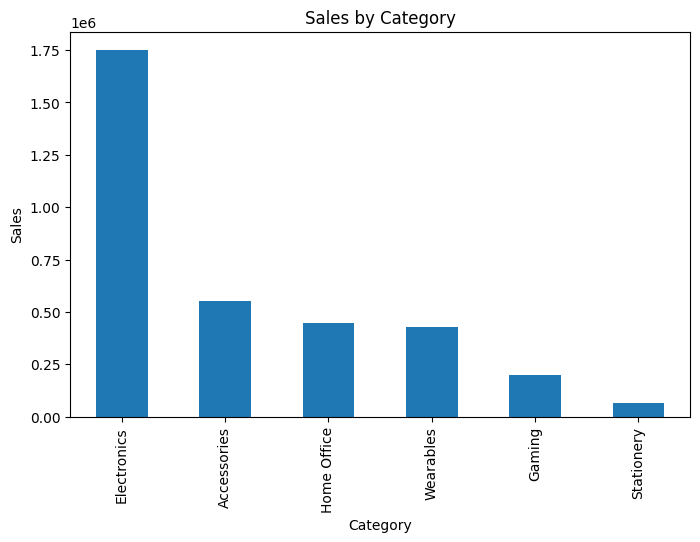

In [ ]:
plt.figure(figsize=(8,5))

category_sales.plot(kind="bar")

plt.title("Sales by Category")

plt.ylabel("Sales")

plt.show()


The bar chart makes the Electronics revenue dominance dramatically visible. The gap between Electronics and the next category (Accessories) is vast, underscoring the importance of the Electronics segment to overall business health.

**9. Time-Based Analysis**

We analyze sales trends over time to identify patterns and changes.



In [ ]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])


Converts the OrderDate column from a string (object) to a proper datetime type. This is a prerequisite for any time-series operations like monthly or yearly grouping.

In [ ]:
monthly_sales = (df.groupby(df["OrderDate"].dt.to_period("M")
    )["Sales"]
    .sum())

monthly_sales

,Sales
OrderDate,
2024-01,121893.0
2024-02,114664.0
2024-03,128150.0
2024-04,115941.0
2024-05,123683.0
2024-06,116784.0
2024-07,128689.0
2024-08,129987.0
2024-09,115943.0


Monthly sales range from ~108,000 to ~131,000 for most of 2024–2025, showing stable and consistent revenue. A notable sharp dip appears in early 2026 (Feb: 75,132; Mar: 84,082), suggesting either incomplete data for those months or a genuine business slowdown.

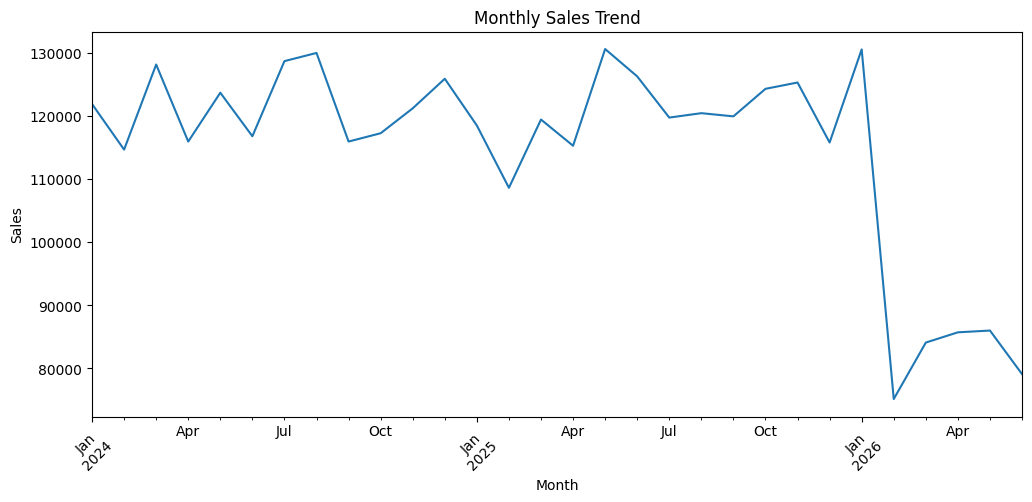

In [ ]:
plt.figure(figsize=(12,5))

monthly_sales.plot()

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.show()


The line chart reveals remarkably stable monthly sales between Jan 2024 and Jan 2026, fluctuating between ~108K and ~131K. The sharp decline from Feb 2026 onward likely reflects incomplete or partial data for those months (the dataset may not cover those months fully). No strong seasonal pattern is apparent in the full data range.

**10. Correlation Analysis**

Correlation analysis helps us understand relationships between numerical variables.



In [ ]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

corr

,OrderID,CustomerID,ProductID,Quantity,Discount,Age,UnitPrice,Sales,OrderValue
OrderID,1.000000,0.002114,0.004012,-0.009637,-0.004664,-0.001657,-0.002537,-0.003431,-0.003431
CustomerID,0.002114,1.000000,-0.003458,0.001314,-0.001541,-0.006141,0.002855,0.005235,0.005235
ProductID,0.004012,-0.003458,1.000000,-0.003227,0.001731,0.003710,0.231946,0.181525,0.181525
Quantity,-0.009637,0.001314,-0.003227,1.000000,0.001848,-0.002204,-0.002164,0.420637,0.420637
Discount,-0.004664,-0.001541,0.001731,0.001848,1.000000,0.003098,0.006917,-0.053738,-0.053738
Age,-0.001657,-0.006141,0.003710,-0.002204,0.003098,1.000000,0.002204,-0.001692,-0.001692
UnitPrice,-0.002537,0.002855,0.231946,-0.002164,0.006917,0.002204,1.000000,0.782302,0.782302
Sales,-0.003431,0.005235,0.181525,0.420637,-0.053738,-0.001692,0.782302,1.000000,1.000000
OrderValue,-0.003431,0.005235,0.181525,0.420637,-0.053738,-0.001692,0.782302,1.000000,1.000000


The strongest correlations with Sales are UnitPrice (0.78) and Quantity (0.42), which makes intuitive sense: higher-priced products and larger order quantities drive higher sales values. Discount has a small negative correlation (-0.054), suggesting discounts slightly reduce sales value. Age has near-zero correlation, confirming the uniform age distribution observed earlier.

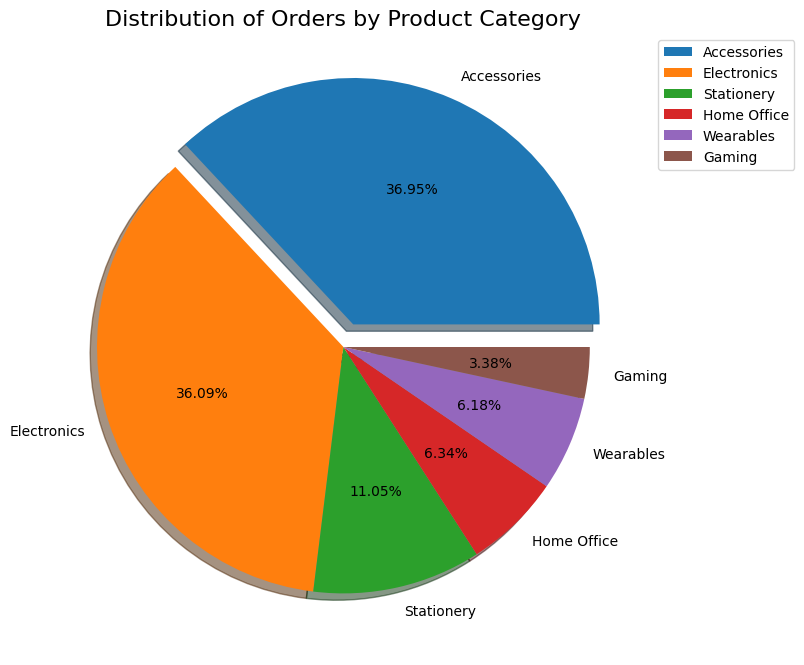

In [ ]:
label = df['Category'].value_counts()
plt.figure(figsize = (12,8))

# Adjust explode and colors to match the number of unique categories (6 categories)
explode = [0.1 if i == 0 else 0 for i in range(len(label))]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

plt.pie(label, labels=label.index, autopct='%1.2f%%', textprops={'fontsize':10}, shadow=True, explode=explode, colors=colors)
plt.title('Distribution of Orders by Product Category', fontdict={"fontsize":16}, pad=10)
plt.legend(bbox_to_anchor=[1,1.01])
plt.show()

This code creates a pie chart showing the distribution of orders across product categories. It counts the records in each category, displays each category’s percentage, highlights the largest slice with an offset, and adds a legend.

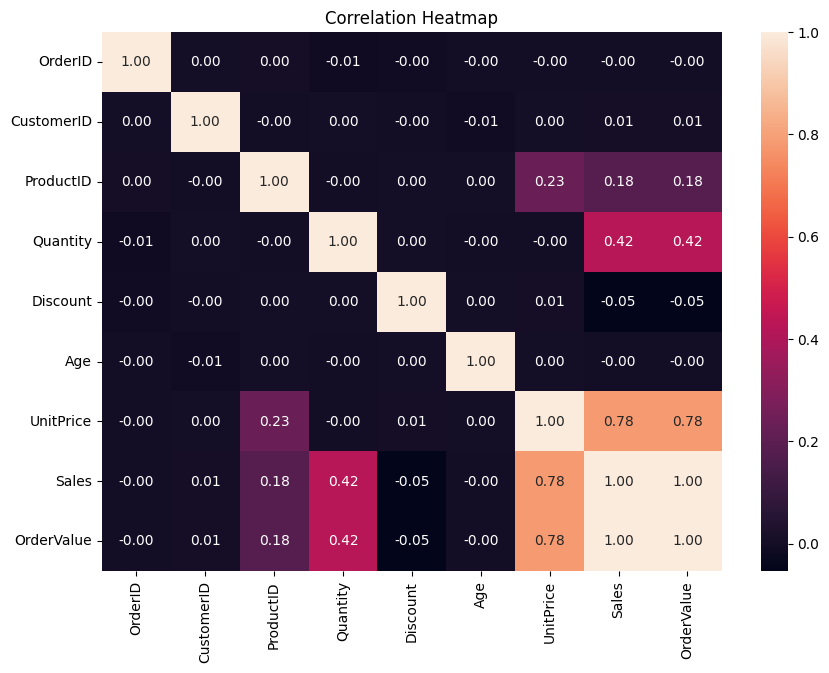

In [ ]:
plt.figure(figsize=(10,7))

sns.heatmap(corr,annot=True,fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()


The heatmap provides a visual summary of all pairwise correlations. The bright warm cell at Sales–UnitPrice (0.78) stands out as the strongest relationship. Sales and OrderValue show a perfect correlation (1.00) because they are the same value. Most other pairs show near-zero correlations, indicating the numeric variables are largely independent of each other — a sign of a well-structured dataset without multicollinearity issues.

**Conclusion**

In this project, exploratory data analysis was performed on e-commerce sales data.

The analysis included:


* Data quality checking

* Customer behavior analysis
  
* Product performance analysis



* Sales trend analysis
  

* Data visualization





The results provide useful insights for understanding business performance and supporting decision-making.